# Hybrid φ: screened nodes and critical threshold

**Internship at CoMuNe Lab** · Riccardo Corte · started on 16 October 2026

**Goal.** This notebook implements screening on a network with message passing. Screening means protecting
some nodes from failure: a screened node never fails, so it always stays in the network. In the message
passing equations (course book v4, sec. 8.2.4, eqs. 8.24-8.25) the quantity we can act on is `φ_i`, the
probability that node `i` stays. Screening a node means setting `φ_i = 1`, while all the other nodes keep the
same `φ`: we call this the **hybrid φ**.

**What we measure.** The main quantity is the critical threshold `φ_c`: below it the giant component
disappears and the network breaks into small pieces (it is not a complete failure: small components remain).
Here `φ_c` is the value of `φ` of the nodes that are **not** screened. We also use the effective `φ`,
`φ_eff = f + (1 − f) φ`, the mean of the `φ_i` over all the nodes: it is the uniform `φ` that gives the same
average protection without choosing where to put it (Artime and De Domenico, arXiv:2104.14893, SI.1), and it is
the reference for the protocols.

**Protocols.** A fraction `f` of the nodes is screened, chosen in three ways:
- **random**: the nodes are drawn at random;
- **degree**: the nodes with the most links. The degree is a local quantity: it only counts the neighbours;
- **betweenness**: the nodes with the highest betweenness, the fraction of the shortest paths between all the
  pairs of nodes that pass through a node (course book v4, eq. 7.36, p. 215). It is a global quantity: it
  measures how much a node is a bridge between different parts of the network.

Degree and betweenness are expected to pick almost the same nodes on scale-free networks grown by preferential
attachment, where the betweenness grows as a power of the degree (course book v4, p. 215), as in Barabási-Albert.
They should separate on networks with communities: the nodes that link two communities have a high
betweenness even with few links. This is why a network with communities is one of the three test networks.

Structure: 0. setup and tools from notebooks 01 and 02; 1. networks; 2. the hybrid φ vector;
3. check of φ_eff; 4. critical threshold: the matrix `M`, `λ(φ)` and the bisection. The applications
(threshold for each protocol, critical budget, curves `S(φ)`) are in notebook 04.

## 0. Setup

In [1]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd
from math import comb


rng = np.random.default_rng(0) 


### 0.1 Tools from notebook 01

Copied unchanged from `01_site_percolation_mp_vs_mc.ipynb` (sections 2b, 3, 4.3 and 6). From notebook 04 on, the same
functions and the new ones written here are imported from `mp.py`.

In [2]:
def message_passing(G, phi, tol=1e-10, max_iter=10000):
    """Site percolation with message passing (course book v4, sec. 8.2.4, eqs. 8.24-8.26).

    phi: a number (the same for all nodes) or a dict {node: phi of that node}.
    Returns S_MP, s (dict node -> s_i), t (dict (i, j) -> t_{i->j}),
    the number of iterations used and whether the iteration has converged.
    """
    #if nx.number_of_selfloops(G) > 0:
    #    raise ValueError("the network has self-loops: against the assumptions of the model")

    nodi = list(G.nodes())
    phi_n = {n: phi for n in nodi} if np.isscalar(phi) else dict(phi)

    # 2|E| messages: two directions for each link
    messaggi = [(i, j) for i, j in G.edges()] + [(j, i) for i, j in G.edges()]  # the "+" joins the two lists: first the links in the direction given by G.edges(), then reversed

    # for each message i->j, the list of messages it has to read
    # (j->k with k in N_j \ {i}) is computed only once, outside the loop.
    # It is the row i->j of the matrix G from the notes of 8 October.
    # In practice, here we build the 0s and 1s of the matrix G
    da_leggere = {(i, j): [(j, k) for k in G.neighbors(j) if k != i] for (i, j) in messaggi}

    t = {m: 1.0 for m in messaggi}       # start far from t = 0, which is always a solution: starting from 0 we would stay there every time, starting from 1 we do not get stuck in it
    converge = False

    for it in range(1, max_iter + 1):
        # synchronous update: all the new messages from the old ones, t_{n+1} = F(t_n)
        t_new = {}
        for (i, j) in messaggi:
            prod = 1.0                   # empty product = 1: for a leaf j we get t_{i->j} = 0
            for m in da_leggere[(i, j)]:
                prod *= 1.0 - t[m]      # this is the product: no link leads to the GCC
            t_new[(i, j)] = phi_n[j] * (1.0 - prod)          # eq. 8.25: at least one leads to the GCC

        # we stop when no message changes by more than tol
        diff = max((abs(t_new[m] - t[m]) for m in messaggi), default=0.0)
        t = t_new
        if diff < tol:
            converge = True
            break

    # eq. 8.24: one s_i per node (an isolated node has an empty product, so s_i = 0)
    s = {}
    for i in nodi:
        prod = 1.0
        for j in G.neighbors(i):
            prod *= 1.0 - t[(i, j)]
        s[i] = phi_n[i] * (1.0 - prod)

    S_MP = sum(s.values()) / len(nodi)   # eq. 8.26, divided by all the N nodes as in mc_1run
    return S_MP, s, t, it, converge


In [3]:
def mc_1run(G, phi, rng):
    """One run of site percolation. Returns S^MC of that run.

    phi: a number (the same for all nodes) or a dict {node: phi of that node},
    as in message_passing.
    """
    nodi = list(G.nodes)
    N = len(nodi)

    # one phi per node, in the same order as nodi
    phi_n = np.full(N, phi) if np.isscalar(phi) else np.array([phi[n] for n in nodi])

    # one value per node: True (1) if the node stays, with its own probability phi
    presente = rng.random(N) < phi_n
    rimasti = [n for n, c in zip(nodi, presente) if c]

    # limit case: no node left
    if len(rimasti) == 0:
        return 0.0

    # graph with only the nodes left and the links between them
    H = G.subgraph(rimasti)

    # connected groups, sorted from the largest to the smallest
    gruppi = sorted(nx.connected_components(H), key=len, reverse=True)
    lcc = gruppi[0]

    return len(lcc) / N


In [4]:
def curve_mc(G, num_runs, num_phis, rng):
    """Monte Carlo curve on a graph: num_phis values of phi between 0 and 1, num_runs runs for each.
    Returns the values of phi and a matrix with one row per phi and one column per run."""
    phis = np.linspace(0, 1, num_phis)

    results = []

    for i in range(len(phis)):
        intermediate = []
        for k in range(num_runs):
            intermediate.append(mc_1run(G, phis[i], rng))
        results.append(intermediate)

    return phis, np.array(results)


In [5]:
def scarto_quadratico_medio(S_a, S_b):
    """Square root of the mean of the squared differences between two curves computed on the same phi."""
    differenze = np.asarray(S_a) - np.asarray(S_b)
    return np.sqrt(np.mean(differenze ** 2))


In [6]:
import scipy.sparse as sp
from scipy.sparse.linalg import eigs


def matrice_G(G):
    """Matrix G of the linearised message passing (notes, Step 5; course book v4, p. 246).
    Rows and columns are the 2|E| messages; G[i->j, j->k] = 1 for every k in N_j other than i.
    Returns G as a sparse CSR matrix and the list of the messages, in the order of the rows."""
    messaggi = [(i, j) for i, j in G.edges()] + [(j, i) for i, j in G.edges()]   # same order as in message_passing
    indice = {m: n for n, m in enumerate(messaggi)}     # message -> its row (and column) number

    righe, colonne = [], []
    for (i, j) in messaggi:
        for k in G.neighbors(j):          # the same loop as da_leggere
            if k != i:
                righe.append(indice[(i, j)])
                colonne.append(indice[(j, k)])

    M = len(messaggi)
    valori = np.ones(len(righe))          # all ones, as floats: eigs works with floating point numbers
    G_mat = sp.csr_matrix((valori, (righe, colonne)), shape=(M, M))
    return G_mat, messaggi


def lambda_max(G_mat):
    """Largest eigenvalue of the sparse matrix G (scipy.sparse.linalg.eigs, ARPACK)."""
    val = eigs(G_mat, k=1, which="LR", return_eigenvectors=False)
    return val[0].real


Check on `K4` at `φ = 0.6`: `S = 19/45`, as in notebook 01.

In [7]:
K4 = nx.complete_graph(4)
S_MP, s, t, it, ok = message_passing(K4, 0.6)
print("S_MP =", S_MP, " 19/45 =", 19 / 45, " converged:", ok)


S_MP = 0.4222222225227878  19/45 = 0.4222222222222222  converged: True


## 1. Networks

Three networks with `N = 1000` nodes:

- **Communities**: stochastic block model, 4 communities of 250 nodes. Inside each community the links are
  placed at random as in Erdős-Rényi; between communities there are only a few links. Mean degree 3 as ER:
  2.8 links inside the community and 0.2 outside, on average.
- **Erdős-Rényi, mean degree 3**.
- **Barabási-Albert, `m = 3`**, as in notebook 01.

In [8]:
# --- parameters ---
N_big = 1000        # number of nodes of each graph
n_blocchi = 4       # communities of the block model, N_big / n_blocchi nodes each
k_dentro = 2.8      # mean number of links of a node inside its own community
k_fuori = 0.2       # mean number of links of a node towards the other communities
k_er = 3            # mean degree of the Erdos-Renyi graph
m_ba = 3            # links brought by each new node in the Barabasi-Albert graph

# link probabilities of the block model: with n nodes per community, a node has n - 1 possible
# partners inside and N_big - n outside, so p = (mean number of links) / (possible partners)
n_com = N_big // n_blocchi
p_dentro = k_dentro / (n_com - 1)
p_fuori = k_fuori / (N_big - n_com)

# --- the three graphs ---
grafi = {
    "communities": nx.stochastic_block_model(
        [N_big // n_blocchi] * n_blocchi,
        [[p_dentro if a == b else p_fuori for b in range(n_blocchi)] for a in range(n_blocchi)],
        seed=1),
    "Erdos-Renyi": nx.gnp_random_graph(N_big, k_er / (N_big - 1), seed=1),
    "Barabasi-Albert": nx.barabasi_albert_graph(N_big, m_ba, seed=1),
}

# --- check: what we have built ---
for nome, g in grafi.items():
    gradi = [d for _, d in g.degree]
    lcc = max(nx.connected_components(g), key=len)
    print(nome)
    print("  nodes:", g.number_of_nodes(), " links:", g.number_of_edges())
    print("  mean degree:", np.mean(gradi), " min:", min(gradi), " max:", max(gradi))
    print("  connected:", nx.is_connected(g), " LCC/N with no removal:", len(lcc) / N_big)

# links between different communities (the block of each node is in the attribute "block")
g = grafi["communities"]
tra = sum(1 for u, v in g.edges() if g.nodes[u]["block"] != g.nodes[v]["block"])
print("communities: links between communities", tra, "out of", g.number_of_edges())


communities
  nodes: 1000  links: 1529
  mean degree: 3.058  min: 0  max: 9
  connected: False  LCC/N with no removal: 0.943
Erdos-Renyi
  nodes: 1000  links: 1486
  mean degree: 2.972  min: 0  max: 9
  connected: False  LCC/N with no removal: 0.934
Barabasi-Albert
  nodes: 1000  links: 2991
  mean degree: 5.982  min: 1  max: 91
  connected: True  LCC/N with no removal: 1.0
communities: links between communities 94 out of 1529


In [9]:
# node positions for the drawings: slow to compute (about 30 s), to be run only once
posizioni = {nome: nx.spring_layout(g, seed=1) for nome, g in grafi.items()}


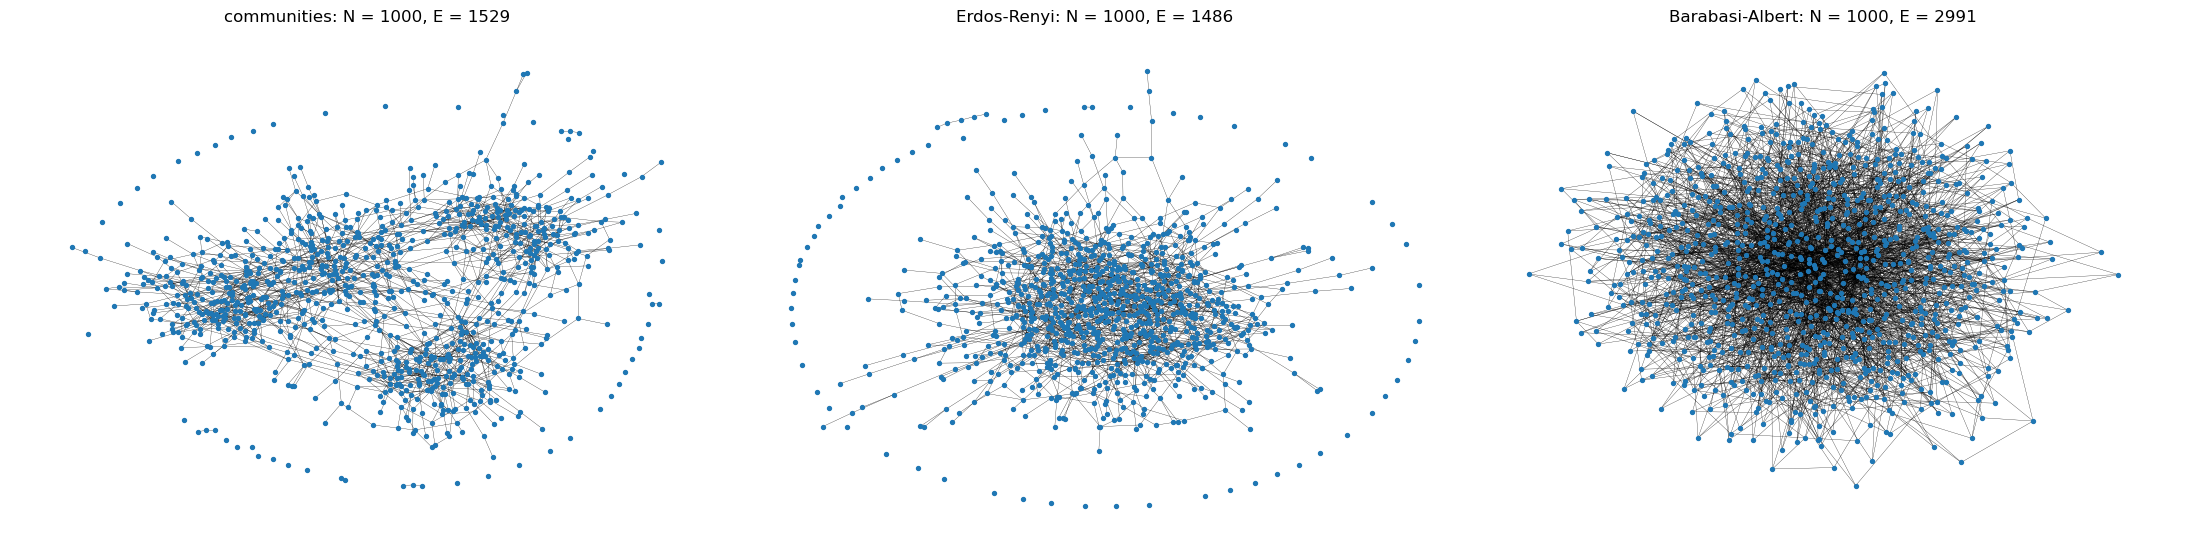

In [10]:
# drawing of the three intact networks; the dictionary reti is also used in the applications
reti = {**grafi}
pos_reti = {**posizioni}

fig, assi = plt.subplots(1, 3, figsize=(22, 5.5))
for ax, (nome, g) in zip(assi, reti.items()):
    nx.draw_networkx(g, pos_reti[nome], ax=ax, node_size=8, width=0.2, with_labels=False, node_color="tab:blue")
    ax.set_title(f"{nome}: N = {g.number_of_nodes()}, E = {g.number_of_edges()}")
    ax.axis("off")
plt.tight_layout()
plt.show()


## 2. The hybrid φ vector

Two separate functions:

1. `estrai_protetti` chooses **which** nodes to screen: the fraction `f` of the nodes, by protocol. *degree*:
   the nodes with the highest degree; *betweenness*: the same, sorted by betweenness; *random*: drawn at random.
   With ties (same degree or betweenness) the choice among them is random.
2. `phi_ibrido` builds the dict `{node: φ_i}` from the screened nodes: `φ_i = 1` for them, `φ` for the others.

Only the first one needs the protocol. Quenched or annealed is decided in the loops that use them: quenched
draws the screened nodes once and keeps them for all the runs, annealed draws them again at every run.

In [11]:
def estrai_protetti(G, frazione, protocollo, rng, betweenness=None):
    """Nodes to screen: the fraction `frazione` of all the nodes, chosen by `protocollo`
    ("random", "degree" or "betweenness"). Ties are broken at random.
    betweenness: dict {node: betweenness} computed once per network with nx.betweenness_centrality;
    if None it is computed here (slow on large networks).
    Returns the list of the screened nodes."""
    num_protetti = int(round(frazione * G.number_of_nodes()))

    # random order of the nodes: for "random" we take the first ones,
    # for the other protocols it decides the order among nodes with the same score
    nodi = list(G.nodes)
    rng.shuffle(nodi)

    if protocollo == "random":
        return nodi[:num_protetti]
    elif protocollo == "degree":
        punteggio = dict(G.degree)
    elif protocollo == "betweenness":
        punteggio = betweenness if betweenness is not None else nx.betweenness_centrality(G)
    else:
        raise ValueError(f"unknown protocol: {protocollo}")

    # sorted keeps the order of the list among equal scores, so the ties stay random
    ordinati = sorted(nodi, key=lambda n: punteggio[n], reverse=True)
    return ordinati[:num_protetti]


def phi_ibrido(G, protetti, phi):
    """Hybrid phi: 1 for the screened nodes, phi for all the others.
    Returns the dict {node: phi of that node}, as accepted by message_passing and mc_1run."""
    phi_n = {n: phi for n in G.nodes}
    for n in protetti:
        phi_n[n] = 1.0
    return phi_n


In [12]:
# communities, top 20% of the nodes by betweenness screened and phi = 0 for the others: no randomness left,
# only the screened nodes stay, so Monte Carlo must give the largest component of the subgraph of the screened nodes
frazione = 0.2
protocollo = "betweenness"
phi_0 = 0.0
g = grafi["communities"]
protetti = estrai_protetti(g, frazione, protocollo, rng, betweenness=None)
phi_n = phi_ibrido(g, protetti, phi_0)
lcc = max(nx.connected_components(g.subgraph(protetti)), key=len)
print("total nodes:", len(g.nodes), "  screened nodes:", len(protetti), "  smallest degree among them:", min(g.degree[n] for n in protetti))
print("Monte Carlo:", mc_1run(g, phi_n, rng), "  largest component of the screened nodes:", len(lcc) / g.number_of_nodes())


total nodes: 1000   screened nodes: 200   smallest degree among them: 2
Monte Carlo: 0.191   largest component of the screened nodes: 0.191


## 3. Check of φ_eff

For each network and each protocol, four curves `S(φ)` on the same values of `φ`, with the fraction `f` of
the nodes screened:

- **(a)** message passing with a single draw of the screened nodes, kept fixed for all the values of `φ` (quenched);
- **(b)** the same with `num_estrazioni` independent draws, mean and standard deviation over the draws;
- **(c)** message passing with `φ_i = φ_eff` for all the nodes (annealed);
- **(d)** Monte Carlo with the same draw as (a).

At every `φ` the dict of the `φ_i` is built again from the same screened nodes: what stays fixed in the quenched
case is the set of screened nodes, not the dict.

`φ_eff` holds only for the **random** protocol, so (c) is the same curve for all the protocols. With random
screening (b) and (c) must agree within the spread over the draws: this is the check of the code. With degree
and betweenness (c) is the reference: the gap between (b) and (c) is what we gain by choosing the screened nodes
instead of drawing them at random. For these two protocols the draws differ only in the ties.

In [13]:
def phi_efficace(phi, frazione):
    """phi_eff = phi + f (1 - phi): probability that a node is present when the fraction f of the nodes,
    chosen at random, is screened (Artime and De Domenico, arXiv:2104.14893, SI.1)."""
    return phi + frazione * (1 - phi)


In [14]:
phis = np.linspace(0, 1, 21)      # 21 values between 0 and 1, step 0.05
frazione = 0.1                     # fraction of the nodes screened
num_estrazioni = 10                # independent draws of the screened nodes for (b)
num_runs_mc = 50                   # Monte Carlo runs per value of phi for (d)
protocolli = ["random", "degree", "betweenness"]

ESEGUI_RUN = False      # True: run again (about 1-2 hours); False: read the results saved in curve_phi_eff.csv

if ESEGUI_RUN:
    righe = []
    for nome, g in grafi.items():
        betw = nx.betweenness_centrality(g)      # once per network

        # (c) annealed: the same phi_eff for all the nodes, the same for all the protocols
        S_c = [message_passing(g, phi_efficace(phi, frazione))[0] for phi in phis]

        for protocollo in protocolli:
            # (a) a single draw, fixed for all the values of phi
            protetti_a = estrai_protetti(g, frazione, protocollo, rng, betw)
            S_a = [message_passing(g, phi_ibrido(g, protetti_a, phi))[0] for phi in phis]

            # (b) a new draw for each curve, one row per draw
            S_b = []
            for e in range(num_estrazioni):
                protetti = estrai_protetti(g, frazione, protocollo, rng, betw)
                S_b.append([message_passing(g, phi_ibrido(g, protetti, phi))[0] for phi in phis])
            S_b = np.array(S_b)

            # (d) Monte Carlo with the draw of (a): the dict of the phi_i is built once per phi,
            # then the num_runs_mc runs differ only in which non-screened nodes fail
            S_d = []
            for phi in phis:
                phi_n = phi_ibrido(g, protetti_a, phi)
                S_d.append(np.mean([mc_1run(g, phi_n, rng) for _ in range(num_runs_mc)]))

            for k, phi in enumerate(phis):
                righe.append({"network": nome, "protocol": protocollo, "phi": phi, "a": S_a[k],
                              "b mean": S_b[:, k].mean(), "b std": S_b[:, k].std(), "c": S_c[k], "d": S_d[k]})

    curve_eff = pd.DataFrame(righe)
    curve_eff.to_csv("risultati/03/curve_phi_eff.csv", index=False)     # saved, so that the run is not needed again
else:
    curve_eff = pd.read_csv("risultati/03/curve_phi_eff.csv")


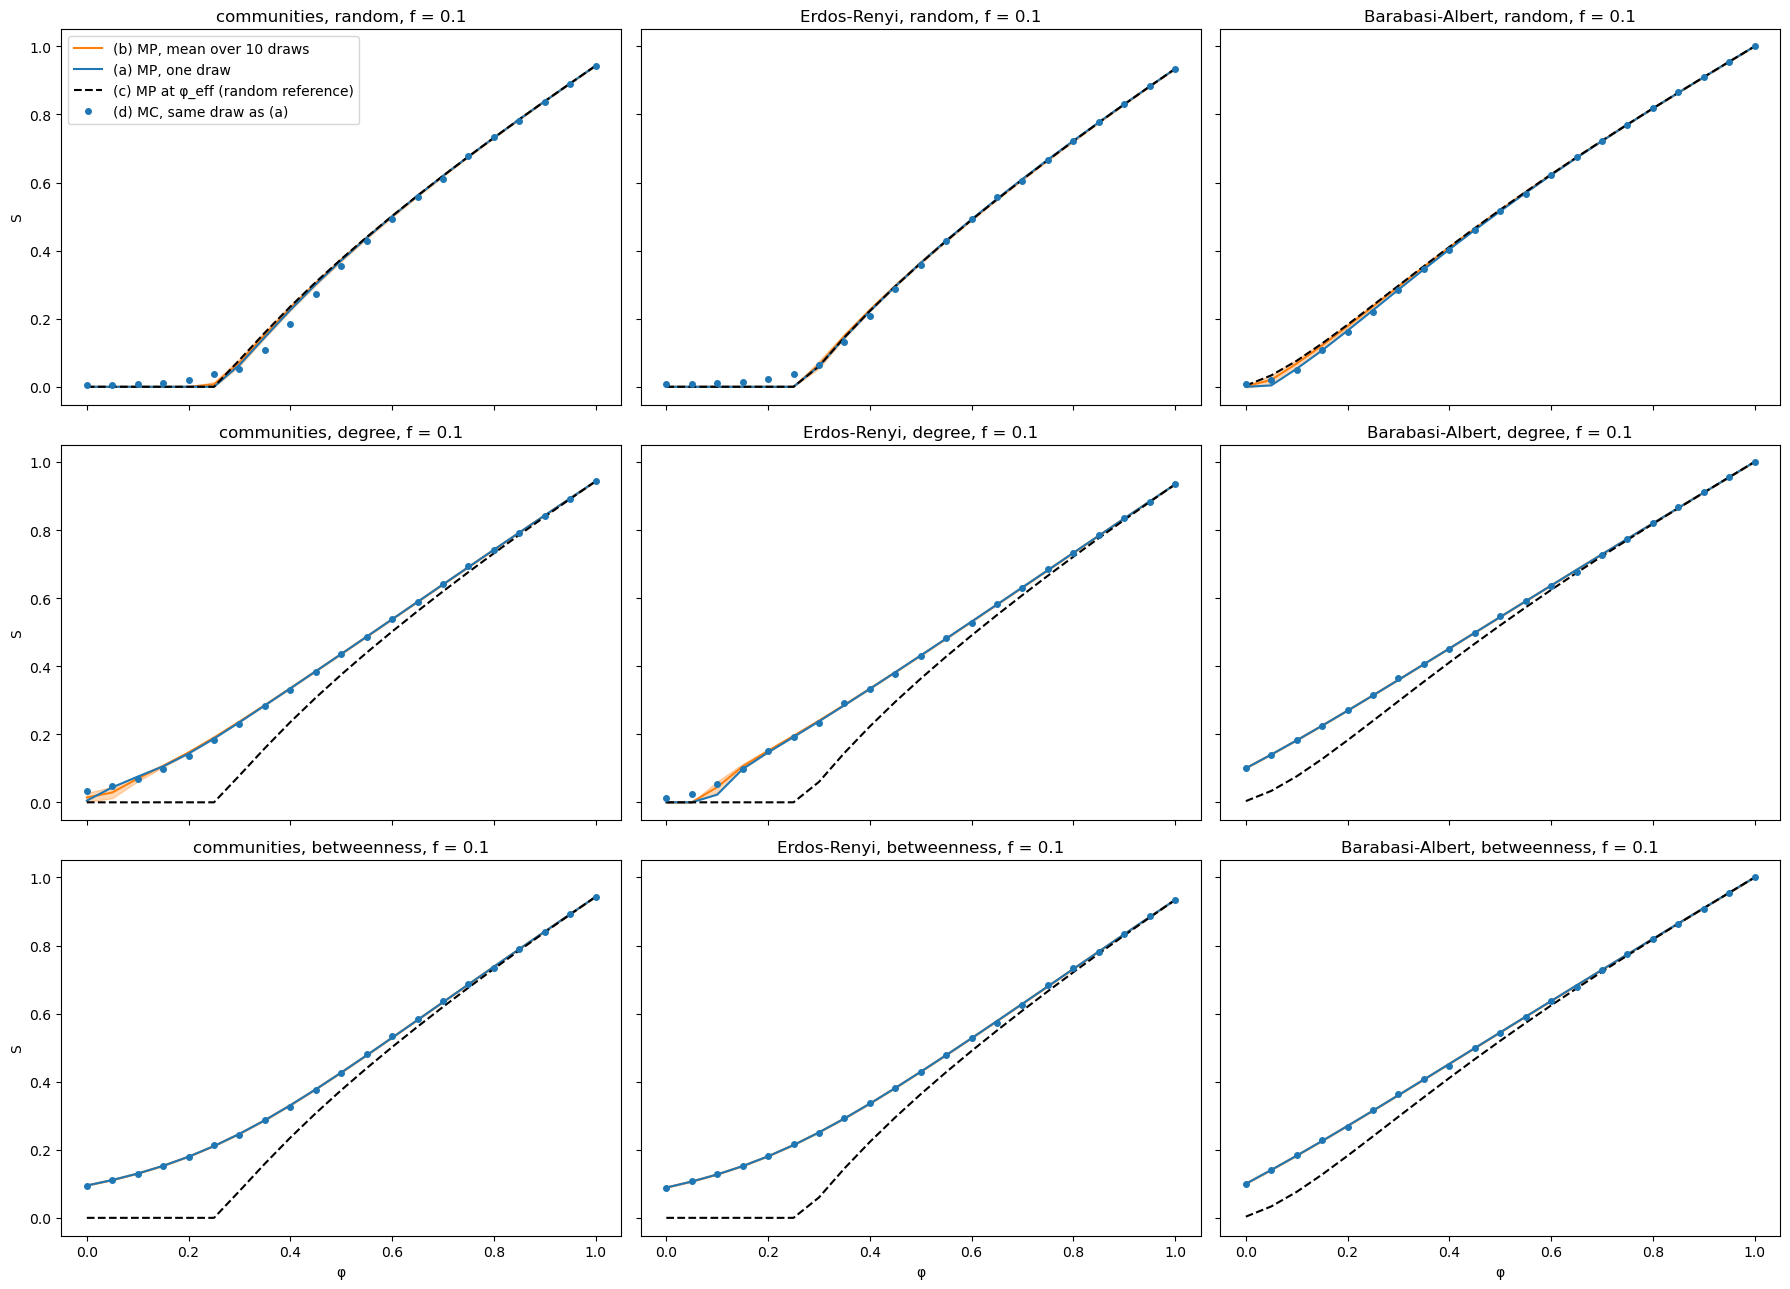

In [15]:
# the four curves: one row per protocol, one column per network
fig, assi = plt.subplots(len(protocolli), len(grafi), figsize=(18, 13), sharex=True, sharey=True)
for r, protocollo in enumerate(protocolli):
    for col, nome in enumerate(grafi):
        ax = assi[r, col]
        t = curve_eff[(curve_eff["network"] == nome) & (curve_eff["protocol"] == protocollo)]
        ax.fill_between(t["phi"], t["b mean"] - t["b std"], t["b mean"] + t["b std"], color="tab:orange", alpha=0.3)
        ax.plot(t["phi"], t["b mean"], color="tab:orange", label=f"(b) MP, mean over {num_estrazioni} draws")
        ax.plot(t["phi"], t["a"], color="tab:blue", label="(a) MP, one draw")
        ax.plot(t["phi"], t["c"], "k--", label="(c) MP at φ_eff (random reference)")
        ax.plot(t["phi"], t["d"], "o", color="tab:blue", ms=4, label="(d) MC, same draw as (a)")
        ax.set_title(f"{nome}, {protocollo}, f = {frazione}")
    assi[r, 0].set_ylabel("S")
for ax in assi[-1]:
    ax.set_xlabel("φ")
assi[0, 0].legend()
plt.tight_layout()
plt.show()


In [16]:
# RMS deviation between the curves, one row per network and protocol
rms_eff = pd.DataFrame({
    (nome, protocollo): {"b vs c": scarto_quadratico_medio(t["b mean"], t["c"]),
                         "a vs d": scarto_quadratico_medio(t["a"], t["d"]),
                         "b vs d": scarto_quadratico_medio(t["b mean"], t["d"]),
                         "c vs d": scarto_quadratico_medio(t["c"], t["d"]),
                         "max b std": t["b std"].max()}
    for (nome, protocollo), t in curve_eff.groupby(["network", "protocol"], sort=False)
}).T
rms_eff.round(4)


b vs c  a vs d  b vs d  c vs d  max b std
communities     random       0.0028  0.0178  0.0193  0.0217     0.0106
                degree       0.0819  0.0073  0.0074  0.0789     0.0167
                betweenness  0.0982  0.0021  0.0021  0.0984     0.0000
Erdos-Renyi     random       0.0016  0.0115  0.0121  0.0117     0.0109
                degree       0.0865  0.0095  0.0073  0.0856     0.0164
                betweenness  0.1035  0.0021  0.0021  0.1039     0.0000
Barabasi-Albert random       0.0039  0.0045  0.0084  0.0111     0.0138
                degree       0.0557  0.0022  0.0021  0.0560     0.0002
                betweenness  0.0560  0.0023  0.0023  0.0563     0.0000

#### Comment on section 3

**Setup.** `f = 0.1` (10% of the nodes screened), 21 values of `φ`, (b) averaged over 10 draws, Monte Carlo (d)
with 50 runs per value of `φ`. Monte Carlo runs on the single draw of (a), which could be an unlucky one: it
checks message passing on that draw, not the average over the draws (that would be Monte Carlo averaged over the
draws). For the random protocol the reference is therefore (c), message passing at `φ_eff`.

**Random (first row).** A single draw (a) stays close to the average over the draws (b) (RMS 0.002-0.008,
largest on Barabási-Albert), and the average over 10 draws matches message passing at `φ_eff` (RMS b vs c
between 0.002 and 0.004): the check of `φ_eff` works, so the hybrid `φ` is built correctly. Monte Carlo follows
the single draw (RMS a vs d 0.005 on Barabási-Albert, 0.012-0.018 on Erdős-Rényi and communities, where below
the threshold Monte Carlo gives small non-zero values: the finite-size effect of notebook 01).

**Degree (second row).** The curves leave the x axis at a lower `φ` than (c): screening the nodes with the most
links lowers the threshold, so the network survives with more of the other nodes failing. `S` becomes non-zero
from `φ ≈ 0.05` on the network with communities and from `φ ≈ 0.1` on Erdős-Rényi; on Barabási-Albert `S = 0.10`
already at `φ = 0`: the screened hubs alone keep a giant component (section 4.2) and the network never collapses.
Here (c) is only the random reference.

On Erdős-Rényi the draws spread the most: many nodes have the same degree and the ties are broken at random, so
each draw screens different nodes. The spread is not uniform in `φ`: the standard deviation of (b) peaks at
`φ = 0.10` (0.016) and is below 0.001 from `φ = 0.4` on. At low `φ` most of the other nodes fail and the giant
component rests on the screened nodes, so which of the tied nodes are screened changes how well they are linked
to each other; at high `φ` almost all the nodes are there anyway and the choice hardly matters. The peak sits at
the threshold because each draw has its own `φ_c`: for the 10 draws of notebook 04, section 1.1 (Erdős-Rényi, degree,
`f = 0.1`) it goes from 0 to 0.103. Close to the threshold `S` grows steeply, so a small shift of `φ_c` gives a
large difference in `S`; below `φ = 0.05` all the draws are under their threshold and the spread is zero again.

**Betweenness (third row).** There are no ties, so all the draws are the same and (a) = (b). On all the three
networks `S ≈ 0.09-0.10` at `φ = 0`: the nodes with the highest betweenness are connected to each other, so with
10% of the nodes screened the giant component never disappears and `φ_c = 0` (as in notebook 04, section 1.1). Message
passing and Monte Carlo agree better than with degree on Erdős-Rényi and communities (RMS a vs d 0.002 against
0.007-0.010); on Barabási-Albert they are the same.

## 4. Critical threshold for each protocol

### 4.1 The matrix M = diag(φ) G

`G` and the list `messaggi` do not depend on `φ`: they are built once per network with `matrice_G`. What changes
with `φ` is only the diagonal: one value per message, in the order of `messaggi`, and for the message `i→j` it is
`φ_j`, the node the message points to (eq. 8.25: `t_{i→j} = φ_j [1 − ∏ (1 − t_{j→k})]`). Multiplying `G` on the
left by the diagonal matrix scales each row by its value.

In [17]:
def matrice_M(G_mat, messaggi, phi_n):
    """M = diag(phi) G of the linearised message passing with node-dependent phi.
    G_mat, messaggi: from matrice_G, built once per network; phi_n: dict {node: phi of that node}.
    The row of the message i->j is multiplied by phi_j. Returns M as a sparse matrix."""
    phi_messaggi = np.array([phi_n[j] for (i, j) in messaggi])    # one value per message, same order as the rows
    return sp.diags(phi_messaggi) @ G_mat


In [18]:
# checks of matrice_M on the three networks:
# 1) uniform phi: M = phi G, so lambda(M) must be phi * lambda_max(G)
# 2) phi = 1 for all the nodes: M = G, so lambda(M) must be lambda_max(G)
phi_prova = 0.3
for nome, g in grafi.items():
    G_mat, messaggi = matrice_G(g)
    lam_G = lambda_max(G_mat)
    lam_1 = lambda_max(matrice_M(G_mat, messaggi, {n: phi_prova for n in g}))
    lam_2 = lambda_max(matrice_M(G_mat, messaggi, {n: 1.0 for n in g}))
    print(f"{nome}: lambda_max(G) = {lam_G:.6f}")
    print(f"  1) phi = {phi_prova}: lambda(M) = {lam_1:.6f}, phi * lambda_max = {phi_prova * lam_G:.6f}")
    print(f"  2) phi = 1:   lambda(M) = {lam_2:.6f}")


communities: lambda_max(G) = 3.068704
  1) phi = 0.3: lambda(M) = 0.920611, phi * lambda_max = 0.920611
  2) phi = 1:   lambda(M) = 3.068704


Erdos-Renyi: lambda_max(G) = 2.931009
  1) phi = 0.3: lambda(M) = 0.879303, phi * lambda_max = 0.879303
  2) phi = 1:   lambda(M) = 2.931009
Barabasi-Albert: lambda_max(G) = 10.744997
  1) phi = 0.3: lambda(M) = 3.223499, phi * lambda_max = 3.223499
  2) phi = 1:   lambda(M) = 10.744997


**Comment on the checks.** `λ(M)` is the largest eigenvalue of the matrix `M = diag(φ) G`. When `φ` is the same
for all the nodes, the diagonal matrix is `φ` times the identity, so `M = φ G`: multiplying a matrix by a number
multiplies all its eigenvalues by that number (if `G v = λ v`, then `(φ G) v = (φ λ) v`, with the same eigenvector).
So `λ(M) = φ λ_max(G)`: for example 0.3 × 3.0687 = 0.9206 on the network with communities. This is the same fact
behind `φ_c = 1/λ_max` of notebook 01: the threshold is where `φ λ_max = 1`.

This holds **only for uniform `φ`**. With the hybrid `φ` the diagonal has 1 on the rows of the messages pointing
to a screened node and `φ` on the others, so it is not a multiple of the identity: `φ` cannot be taken out of `M`,
and the eigenvalues of `M` depend on which rows have 1. There is no closed formula for `φ_c` any more: it is found
numerically, by bisection on `λ(M(φ)) = 1` (sections 4.2 and 4.3). The checks above test `matrice_M` in the case
where the answer is known, before using it where it is not.

### 4.2 λ(φ) is non-decreasing

`λ(φ)` is the largest eigenvalue of `M(φ)`. With uniform `φ` it is `φ λ_max`, a straight line, so the check is
already done in section 4.1. Here the hybrid `φ`: the screened nodes (fraction `f = 0.05`, one draw, kept fixed)
at 1, all the others at `φ`, with `φ` from 0 to 1, for the three protocols. On the x axis `φ_eff = φ + f(1 − φ)`,
so the uniform curve at `φ_eff` (dashed) is the reference: a curve above it means that the protocol gives a
larger eigenvalue, and so a lower threshold, than spreading the same protection at random. The threshold is
where a curve crosses 1.

At `φ = 0` only the rows of the messages pointing to a screened node survive, and the nonzero entries of those
rows point to messages leaving that screened node towards another screened node. So every chain of nonzero
entries runs only through screened nodes, and `λ(0)` is the largest eigenvalue of the matrix `G` of the
**subgraph of the screened nodes alone**. If the screened nodes form a forest (no cycles among them), `λ(0) = 0`:
a message can never come back. This matrix is small, so it is computed directly (`np.linalg.eigvals`) when it has fewer than 2000 rows: with few screened nodes `M` at `φ = 0`
is almost empty and `eigs` may fail to converge.

In [19]:
def lambda_zero(g, protetti):
    """lambda(0): largest eigenvalue of G built on the subgraph of the screened nodes alone."""
    H = g.subgraph(protetti)
    if H.number_of_edges() == 0:
        return 0.0
    G_H = matrice_G(H)[0]
    if G_H.shape[0] < 2000:
        return np.max(np.linalg.eigvals(G_H.toarray()).real)
    return lambda_max(G_H)


communities, random: non-decreasing True, lambda(0) = 0.000, lambda(1) = 3.069


communities, degree: non-decreasing True, lambda(0) = 0.000, lambda(1) = 3.069


communities, betweenness: non-decreasing True, lambda(0) = 0.000, lambda(1) = 3.069


Erdos-Renyi, random: non-decreasing True, lambda(0) = 0.000, lambda(1) = 2.931


Erdos-Renyi, degree: non-decreasing True, lambda(0) = 0.000, lambda(1) = 2.931


Erdos-Renyi, betweenness: non-decreasing True, lambda(0) = 0.000, lambda(1) = 2.931


Barabasi-Albert, random: non-decreasing True, lambda(0) = 0.000, lambda(1) = 10.745


Barabasi-Albert, degree: non-decreasing True, lambda(0) = 6.005, lambda(1) = 10.745


Barabasi-Albert, betweenness: non-decreasing True, lambda(0) = 6.157, lambda(1) = 10.745


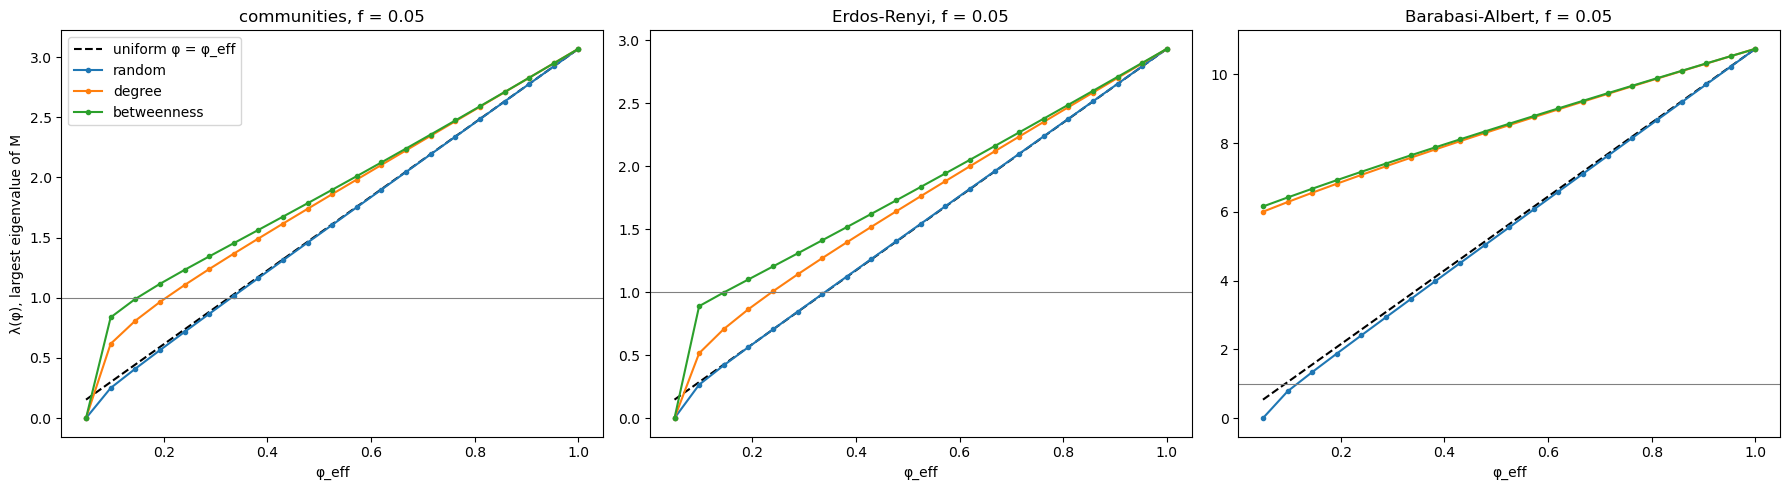

In [20]:
frazione_42 = 0.05
phis_42 = np.linspace(0, 1, 21)

fig, assi = plt.subplots(1, len(grafi), figsize=(18, 5))
for ax, (nome, g) in zip(assi, grafi.items()):
    G_mat, messaggi = matrice_G(g)
    betw = nx.betweenness_centrality(g)
    phi_eff = phi_efficace(phis_42, frazione_42)

    # uniform phi at phi_eff: lambda = phi_eff * lambda_max (section 4.1)
    ax.plot(phi_eff, phi_eff * lambda_max(G_mat), "k--", label="uniform φ = φ_eff")

    for protocollo in protocolli:
        protetti = estrai_protetti(g, frazione_42, protocollo, rng, betw)
        # at phi = 0 lambda_zero (subgraph of the screened nodes, section 4.3): there eigs is not reliable,
        # M is almost empty and eigs can return small spurious values instead of 0
        lam = [lambda_zero(g, protetti) if phi == 0 else
               lambda_max(matrice_M(G_mat, messaggi, phi_ibrido(g, protetti, phi))) for phi in phis_42]
        ax.plot(phi_eff, lam, "o-", ms=3, label=protocollo)
        # numerical check: lambda never goes down as phi grows (up to the precision of eigs)
        print(f"{nome}, {protocollo}: non-decreasing {np.all(np.diff(lam) >= -1e-9)}, "
              f"lambda(0) = {lam[0]:.3f}, lambda(1) = {lam[-1]:.3f}")

    ax.axhline(1, color="gray", lw=0.8)
    ax.set_title(f"{nome}, f = {frazione_42}")
    ax.set_xlabel("φ_eff")
assi[0].set_ylabel("λ(φ), largest eigenvalue of M")
assi[0].legend()
plt.tight_layout()
plt.show()


**Comment on section 4.2.** The main result is that `λ(φ)` is **non-decreasing** in all the nine cases, as
expected from Perron-Frobenius: it is what the bisection of section 4.3 needs, because a curve that only goes up
crosses 1 at most once. The curves are not straight lines: only the uniform one, `λ = φ_eff λ_max` (dashed), is.

The dashed line is the random reference, and the random protocol lies on it or slightly below. Degree and
betweenness lie above it on all the networks: at the same `φ_eff`, `λ` is larger, so the curve reaches 1 at a
smaller `φ` and the threshold is **lower**. A larger `λ` does not raise the threshold, it lowers it: the giant
component exists when `λ ≥ 1`.

At `φ = 0` only the screened nodes are left and `λ(0)` is the largest eigenvalue of their subgraph. With
`f = 0.05` it is 0 on Erdős-Rényi and on the network with communities for all the protocols: there the screened
nodes form a forest (no cycles), so a message can never come back. On Barabási-Albert, with degree and
betweenness, `λ(0) ≈ 6`: the 50 screened hubs share 128 links and many cycles, and they keep a giant component
alone, so `φ_c = 0`. The small difference between betweenness and degree there (6.16 against 6.00, one draw) is
not a result.

On Erdős-Rényi and communities the curves of degree and betweenness jump between `φ = 0` and the first point of
the grid. It is not a threshold: `λ` is continuous, but it grows very steeply as soon as `φ > 0` (Erdős-Rényi,
betweenness: `λ = 0.58` already at `φ = 0.0001`, 0.89 at `φ = 0.05`, 1 at `φ ≈ 0.1`; check outside this notebook).
Our reading, a hypothesis not checked: the screened nodes are close to each other but without cycles, and a few
non-screened nodes are enough to close cycles made almost only of screened nodes. The jump brings `λ` close to 1
but not above it: the giant component appears only at `φ ≈ 0.1`, still much lower than with random screening.

### 4.3 Threshold by bisection

`λ(φ)` is non-decreasing (section 4.2), so it crosses 1 at most once and the threshold can be found by
bisection on `[0, 1]`: compute `λ` at the midpoint, keep the half where the crossing is, repeat until the
interval is shorter than `tol`. Each step halves the interval, so `tol = 1e-4` takes 14 steps, one `eigs`
each. Two special cases are checked first:

- `λ(0) ≥ 1`: the screened nodes alone already percolate, the giant component exists for every `φ`, so `φ_c = 0`;
- `λ(1) < 1`: the network does not percolate even when intact, there is no threshold (`nan`).

The function gets the screened nodes, not the dict of the `φ_i`, because the dict changes at every step.

In [21]:
def soglia_bisezione(g, G_mat, messaggi, protetti, tol=1e-4):
    """Critical threshold phi_c with hybrid phi: lambda(phi) = 1, with lambda the largest eigenvalue of
    M = diag(phi) G, the screened nodes at phi = 1 and all the others at phi.
    G_mat, messaggi: from matrice_G, built once per network. Returns phi_c (0 if the screened nodes alone
    percolate, nan if the network does not percolate even when intact)."""
    def lam(phi):
        M = matrice_M(G_mat, messaggi, phi_ibrido(g, protetti, phi))
        if M.count_nonzero() == 0:      # all entries zero (e.g. phi = 0 and no screened node): eigs fails, lambda = 0
            return 0.0
        return lambda_max(M)

    # special cases
    if lambda_zero(g, protetti) >= 1:
        return 0.0
    if lam(1.0) < 1:
        return np.nan

    basso, alto = 0.0, 1.0
    while alto - basso > tol:
        medio = (basso + alto) / 2
        if lam(medio) < 1:          # below the threshold: the crossing is in the upper half
            basso = medio
        else:                       # above the threshold: the crossing is in the lower half
            alto = medio
    return (basso + alto) / 2


In [22]:
# checks of soglia_bisezione on the three networks:
# 1) no screened node (f = 0): phi_c must be 1/lambda_max, as in section 6 of notebook 01
# 2) random screening, f = 0.05: phi_c close to (1/lambda_max - f)/(1 - f), the annealed value (guide, sec. 5.4);
#    mean and spread over a few draws, since each draw is quenched
frazione_43 = 0.05
for nome, g in grafi.items():
    G_mat, messaggi = matrice_G(g)
    lam_G = lambda_max(G_mat)
    phi_c_0 = soglia_bisezione(g, G_mat, messaggi, [])
    print(f"{nome}: 1) f = 0: phi_c = {phi_c_0:.5f}, 1/lambda_max = {1 / lam_G:.5f}")

    soglie = [soglia_bisezione(g, G_mat, messaggi, estrai_protetti(g, frazione_43, "random", rng))
              for _ in range(5)]
    print(f"  2) random, f = {frazione_43}: phi_c = {np.mean(soglie):.4f} ± {np.std(soglie):.4f}, "
          f"annealed (1/lambda_max - f)/(1 - f) = {(1 / lam_G - frazione_43) / (1 - frazione_43):.4f}")


communities: 1) f = 0: phi_c = 0.32590, 1/lambda_max = 0.32587


  2) random, f = 0.05: phi_c = 0.2926 ± 0.0107, annealed (1/lambda_max - f)/(1 - f) = 0.2904
Erdos-Renyi: 1) f = 0: phi_c = 0.34116, 1/lambda_max = 0.34118


  2) random, f = 0.05: phi_c = 0.3065 ± 0.0097, annealed (1/lambda_max - f)/(1 - f) = 0.3065


Barabasi-Albert: 1) f = 0: phi_c = 0.09305, 1/lambda_max = 0.09307


  2) random, f = 0.05: phi_c = 0.0496 ± 0.0286, annealed (1/lambda_max - f)/(1 - f) = 0.0453


**Comment on section 4.3.** Both checks pass on the three networks.

1. With `f = 0` no node is screened, the hybrid `φ` is a uniform `φ`, and the bisection gives back the analytical
   threshold `1/λ_max` within the tolerance: 0.32590 against 0.32587 (communities), 0.34116 against 0.34118
   (Erdős-Rényi), 0.09305 against 0.09307 (Barabási-Albert), differences below `tol/2 = 5·10⁻⁵`.
2. With random screening the reference comes from `φ_eff`. With annealed random screening every node is present
   with the same probability `φ_eff = f + (1 − f) φ`, whatever its degree, so for message passing the network
   is the same as uniform percolation at `φ_eff` (Artime and De Domenico, SI.1). Uniform percolation breaks at
   `φ_eff = 1/λ_max`, so `f + (1 − f) φ_c = 1/λ_max`, which gives
   `φ_c = (1/λ_max − f)/(1 − f)`. When `f ≥ 1/λ_max` this is negative: the screened nodes alone are enough and
   `φ_c = 0` (this is why the dashed curve of notebook 04, section 1.1 is cut at 0). The formula is annealed, while the
   bisection works on one fixed draw (quenched), so we compare it with the mean over 5 draws: 0.2926 ± 0.0107
   against 0.2904 (communities), 0.3065 ± 0.0097 against 0.3065 (Erdős-Rényi), 0.0496 ± 0.0286 against
   0.0453 (Barabási-Albert), all within the spread over the draws.

The applications of the hybrid `φ` to the three test networks (threshold for each protocol, critical
budget `f*`, total robustness, check against Monte Carlo, curves `S(φ)`) are in notebook 04.